# Lecture 9 · A first PyTorch model

Can a computer read a handwritten zero? You'll start with the numbers in one image, build a model that gives each possible digit a score, and watch one training step change its answers. At the end you'll draw a stroke across a zero and see which digit the model reads.

Run the cells from top to bottom. You'll need Python, PyTorch, Matplotlib, and scikit-learn. In a fresh Jupyter environment, run `%pip install torch matplotlib scikit-learn` first. The digits come with scikit-learn. A CPU is enough.

## 1. What does PyTorch see in an image?

On a grayscale screen, each pixel has one brightness value. Here are four pixels in two rows. `torch.tensor` takes those numbers and stores them in a rectangular array called a **tensor**. `shape` gives the lengths of its axes, `dtype` tells us how the numbers are stored, and `device` tells us where the computation will run.

In [1]:
import torch

patch = torch.tensor([[0., 8.], [16., 4.]])
print(patch)
print(patch.shape, patch.dtype, patch.device)

tensor([[ 0.,  8.],
        [16.,  4.]])
torch.Size([2, 2]) torch.float32 cpu


Indices start at zero. `patch[1, 0]` selects the first pixel of the second row. Dividing a tensor by a number divides every entry, so we can convert brightnesses from the range 0–16 to 0–1 in one operation. What value should the bottom-left pixel have after division?

In [2]:
print(patch[1, 0])
print(patch / 16)

tensor(16.)
tensor([[0.0000, 0.5000],
        [1.0000, 0.2500]])


A real image in our dataset has eight rows of eight pixels. `images[i]` and `labels[i]` belong together: one is the picture, the other is the digit the person wrote. We convert the pixels to floating-point numbers for multiplication by learned weights. We keep the labels as integers because each is a class index from 0 to 9.

In [3]:
from sklearn.datasets import load_digits
import matplotlib.pyplot as plt

digits = load_digits()
images = torch.tensor(digits.images, dtype=torch.float32) / 16
labels = torch.tensor(digits.target, dtype=torch.long)
print(images.shape, labels.shape)

torch.Size([1797, 8, 8]) torch.Size([1797])


There are 1,797 images. Selecting one leaves an `(8, 8)` tensor. `imshow` turns those numbers back into a picture. White pixels are ink. `.item()` reads a single value from a tensor as a Python number. Try `i = 1` and compare the ink in the middle of the two digits.

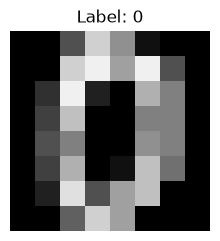

In [4]:
i = 0
plt.figure(figsize=(2.6, 2.6))
plt.imshow(images[i], cmap="gray", vmin=0, vmax=1, interpolation="nearest")
plt.title(f"Label: {labels[i].item()}")
plt.axis("off")
plt.show()

## 2. How does an image become a prediction?

Take four images together. This is a **batch**. Axis 0 tells us *which image*, and axes 1 and 2 tell us *which pixel*. A linear layer expects a row of inputs per example. `flatten(start_dim=1)` joins the last two axes into a row of 64 pixels and keeps the four images separate. Predict both shapes before running the cell.

In [5]:
batch = images[:4]
rows = batch.flatten(start_dim=1)
print("Images:", batch.shape)
print("Rows of pixels:", rows.shape)

Images: torch.Size([4, 8, 8])
Rows of pixels: torch.Size([4, 64])


For each digit, give every pixel a weight. Multiply the 64 brightnesses by their weights, add the products, and add a bias. That sum is the digit's **score**. A positive weight means brighter ink at that position raises the score.

`torch.nn` contains PyTorch’s building blocks for neural networks. We import it as `nn`. Its `Linear(64, 10)` layer does this calculation for all ten digits. It stores a `weight` tensor with ten rows and a `bias` tensor with ten entries. These are **parameters**: PyTorch tracks derivatives for them, and an optimizer can change them during training. The initial values are random. Setting the seed makes today's starting point reproducible.

In [6]:
from torch import nn

torch.manual_seed(9)
layer = nn.Linear(64, 10)
print("Weights:", layer.weight.shape, " Bias:", layer.bias.shape)
print("Weights track gradients:", layer.weight.requires_grad)

Weights: torch.Size([10, 64])  Bias: torch.Size([10])
Weights track gradients: True


Let's check one score before trusting the layer. `rows[0]` is the first image. `layer.weight[3]` contains the weights for digit 3. `*` pairs each pixel with its own weight, and `sum()` adds the 64 contributions. Calling `layer(rows)` calculates all 40 scores at once. Which entry should match the value we computed?

In [7]:
score_for_3 = (rows[0] * layer.weight[3]).sum() + layer.bias[3]
scores = layer(rows)
print("One image, digit 3 by hand:", round(score_for_3.item(), 5))
print("The same entry from the layer:", round(scores[0, 3].item(), 5))
print("All scores:", scores.shape)

One image, digit 3 by hand: -0.0371
The same entry from the layer: -0.0371
All scores: torch.Size([4, 10])


A PyTorch **module** is an object you can call to perform a calculation. `nn.Sequential` connects modules in order. We'll put `nn.Flatten()` before the same linear layer so we can pass images directly to `model`. This call is the **forward pass**. Its output has one row per image and one column per digit. `argmax(dim=1)` picks the column with the largest score in each row. These first guesses use the initial weights.

In [8]:
model = nn.Sequential(nn.Flatten(), layer)
scores = model(batch)
print("Guessed digits:", scores.argmax(dim=1).tolist())
print("Written digits:", labels[:4].tolist())

Guessed digits: [0, 0, 0, 0]
Written digits: [0, 1, 2, 3]


## 3. What does `backward()` actually calculate?

Shrink the classifier to **one pixel, two possible digits, and one adjustable weight** $w$. Give digit 0 a fixed score of 0 and digit 1 a score of $0.5w$. The correct digit is 1. When $w=0$, the scores are tied. Would increasing $w$ help?

`nn.CrossEntropyLoss()` takes raw scores and a correct class index. Internally it converts the scores to probabilities using softmax and takes the negative log of the probability assigned to the correct class. Here the loss starts at $-\log(1/2)\approx0.693$. `requires_grad=True` tells PyTorch to remember how the result depends on $w$.

In [9]:
loss_fn = nn.CrossEntropyLoss()
w = torch.tensor(0., requires_grad=True)
two_scores = w * torch.tensor([[0., 0.5]])
loss = loss_fn(two_scores, torch.tensor([1]))
print("Scores:", two_scores.tolist(), " Loss:", round(loss.item(), 3))
print("Gradient before backward:", w.grad)

Scores: [[0.0, 0.0]]  Loss: 0.693
Gradient before backward: None


On the forward pass, PyTorch recorded the operations from $w$ to the scores to the loss. `loss.backward()` walks through them in reverse using the chain rule. At the tie, the loss changes at rate $0.5-1=-0.5$ with respect to the correct digit's score (the softmax probability minus the target). That score changes at rate $0.5$ with respect to $w$. Multiplying gives $-0.25$.

Where did that number go? Inspect `w.grad`, then inspect `w` itself.

In [10]:
loss.backward()
print("Derivative stored in w.grad:", w.grad.item())
print("Weight after backward:", w.item())

Derivative stored in w.grad: -0.25
Weight after backward: 0.0


The derivative is negative. A small increase in $w$ should lower the loss. `torch.optim.SGD` implements the update $w \leftarrow w-\eta\,w.\mathrm{grad}$. With learning rate $\eta=1$, the first call to `step()` should move $w$ from 0 to 0.25. Recomputing the scores with the new weight lets us test the prediction. To repeat this experiment from zero, rerun all three cells in this section.

In [11]:
toy_optimizer = torch.optim.SGD([w], lr=1.0)
toy_optimizer.step()
new_scores = w * torch.tensor([[0., 0.5]])
print("Updated weight:", w.item())
print("New loss:", round(loss_fn(new_scores, torch.tensor([1])).item(), 3))

Updated weight: 0.25
New loss: 0.633


## 4. Train the digit reader

Return to the ten-digit model. Reserve the last 300 images for testing. `TensorDataset` pairs each training image with its label. `DataLoader` shuffles those pairs and hands us up to 64 at a time. Unpacking one batch gives us the pictures and their correct answers in the same order.

In [12]:
from torch.utils.data import DataLoader, TensorDataset

train_data = TensorDataset(images[:-300], labels[:-300])
batches = DataLoader(train_data, batch_size=64, shuffle=True)
test_images, test_labels = images[-300:], labels[-300:]
pictures, answers = next(iter(batches))
print("One training batch:", pictures.shape, answers.shape)

One training batch: torch.Size([64, 8, 8]) torch.Size([64])


We can now write one training step. `model.parameters()` gives the optimizer the weights and biases we inspected earlier.

1. Clear the old gradients with `zero_grad()`. Successive backward passes add to the gradients already stored.
2. Run the pictures through the model. Compare the ten scores for each picture with its label to get one mean loss.
3. Call `backward()` to compute a derivative for each weight and bias.
4. Call `step()` to update those parameters. The next forward pass will use their new values.

In [13]:
optimizer = torch.optim.SGD(model.parameters(), lr=0.2)

def train_batch(pictures, answers):
    optimizer.zero_grad()
    scores = model(pictures)
    loss = loss_fn(scores, answers)
    loss.backward()
    optimizer.step()

Try the step once before writing a loop. Measure the loss on **the same 64 pictures** on either side of the update. Using the same batch lets us see the effect of changing just the parameters.

In [14]:
before = loss_fn(model(pictures), answers).item()
train_batch(pictures, answers)
after = loss_fn(model(pictures), answers).item()
print(f"Loss on this batch: {before:.3f} → {after:.3f}")

Loss on this batch: 2.322 → 2.222


One pass through every training batch is an **epoch**. Train for 15 epochs. To see how a prediction changes, watch the model guess the first six test digits before and after training. Their labels are used only for the comparison.

In [15]:
print("Before the 15 epochs:", model(test_images[:6]).argmax(dim=1).tolist())
for epoch in range(15):
    for pictures, answers in batches:
        train_batch(pictures, answers)
print("After the 15 epochs: ", model(test_images[:6]).argmax(dim=1).tolist())
print("Written digits:      ", test_labels[:6].tolist())

Before the 15 epochs: [6, 0, 6, 4, 4, 6]
After the 15 epochs:  [6, 3, 2, 1, 7, 4]
Written digits:       [6, 3, 2, 1, 7, 4]


## 5. Read a new digit, then change it

For prediction, `model.eval()` switches layers to evaluation mode. This particular model contains only flattening and a linear layer, so both behave the same in either mode. `torch.no_grad()` serves a separate purpose: it lets us calculate scores without recording a backward pass. In the last line, `predictions == test_labels` compares each guess with its label, and `sum()` counts the matches.

In [16]:
model.eval()
with torch.no_grad():
    predictions = model(test_images).argmax(dim=1)
correct = (predictions == test_labels).sum().item()
print(f"Correctly read {correct} of {len(test_labels)} held-out digits")

Correctly read 263 of 300 held-out digits


Find a zero in the held-out images. `clone()` makes a copy we can draw on without changing the original. The assignment below paints a white horizontal stroke on row 3, from column 2 through column 5. Will the digit reader keep its answer? Look at the two pictures before running the prediction cell.

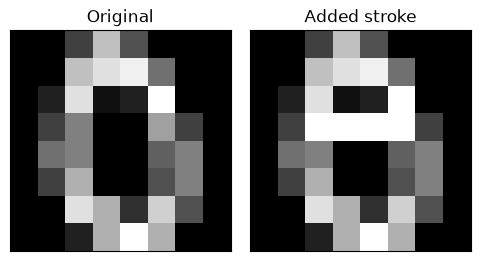

In [17]:
zero_index = (test_labels == 0).nonzero()[0].item()
original = test_images[zero_index]
edited = original.clone()
edited[3, 2:6] = 1.0
fig, axes = plt.subplots(1, 2, figsize=(4.8, 2.5), layout="constrained")
for ax, picture, title in zip(axes, (original, edited), ("Original", "Added stroke")):
    ax.imshow(picture, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    ax.set(title=title, xticks=[], yticks=[])
plt.show()

`torch.stack` puts the two pictures into a batch of shape `(2, 8, 8)`. Read the winning digit and the scores for 0, 8, and 9. All three can have a loop in their handwriting. Which one gained the most from the new stroke?

In [18]:
with torch.no_grad():
    pair_scores = model(torch.stack([original, edited]))
for name, row in zip(("Original", "Edited"), pair_scores):
    print(f"{name}: guessed {row.argmax().item()} | 0: {row[0]:.2f} | 8: {row[8]:.2f} | 9: {row[9]:.2f}")

Original: guessed 0 | 0: 4.42 | 8: 0.19 | 9: 1.57
Edited: guessed 9 | 0: 2.61 | 8: 1.34 | 9: 3.58


In this run the guess changes from **0 to 9**. Adding ink lowers the score for 0 and raises the score for 8, but 9 finishes ahead of both. Each digit has its own row of weights, so the same four pixels can help one digit and hurt another. Move the stroke down one row and rerun the last two cells. Does the model still read a 9?

## Tutorials

The PyTorch beginner series covers each operation in more depth. [Tensors](https://docs.pytorch.org/tutorials/beginner/basics/tensorqs_tutorial.html) · [Building a neural network](https://docs.pytorch.org/tutorials/beginner/basics/buildmodel_tutorial.html) · [Autograd](https://docs.pytorch.org/tutorials/beginner/basics/autogradqs_tutorial.html) · [Datasets and DataLoaders](https://docs.pytorch.org/tutorials/beginner/basics/data_tutorial.html) · [The optimization loop](https://docs.pytorch.org/tutorials/beginner/basics/optimization_tutorial.html)

The handwritten images are bundled with scikit-learn. [Digits dataset](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html)